In [16]:
import os
ROOT_ALL = '/kaggle/input/datasets/ipythonx/mvtec-ad'
print(os.listdir(ROOT_ALL))

['wood', 'screw', 'metal_nut', 'capsule', 'readme.txt', 'hazelnut', 'carpet', 'pill', 'license.txt', 'grid', 'zipper', 'transistor', 'tile', 'leather', 'toothbrush', 'bottle', 'cable']


In [17]:
ROOT = '/kaggle/input/datasets/ipythonx/mvtec-ad/bottle'

for sub in ['train', 'test', 'ground_truth']:
    p = os.path.join(ROOT, sub)
    if os.path.isdir(p):
        print(sub, '→', os.listdir(p))

train → ['good']
test → ['good', 'contamination', 'broken_large', 'broken_small']
ground_truth → ['contamination', 'broken_large', 'broken_small']


正常圖檔名: 000.png
瑕疵圖檔名: 000.png
遮罩資料夾內容: ['000_mask.png', '001_mask.png', '002_mask.png']


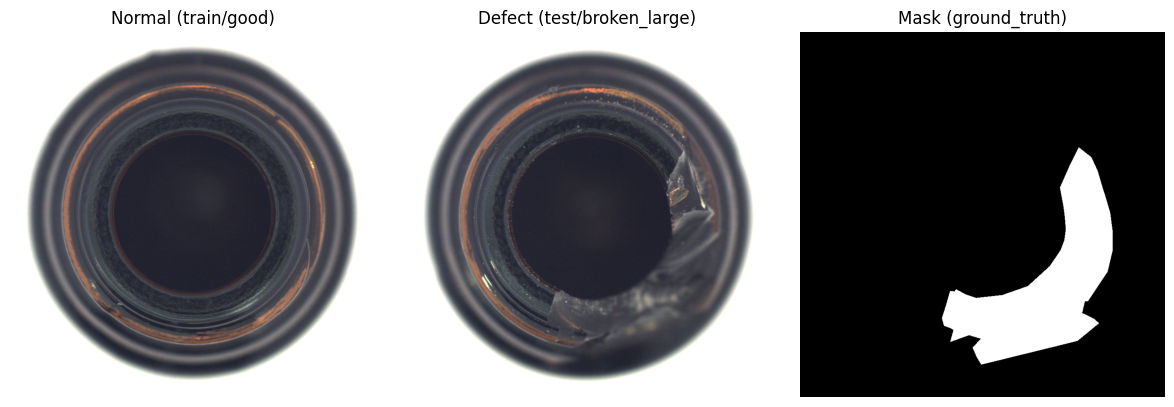

In [18]:
from PIL import Image
import matplotlib.pyplot as plt

defect = 'broken_large'   # 從 test 底下挑一種瑕疵

normal_dir = os.path.join(ROOT, 'train', 'good')
defect_dir = os.path.join(ROOT, 'test', defect)
mask_dir   = os.path.join(ROOT, 'ground_truth', defect)

# 各挑第一張
normal_name = sorted(os.listdir(normal_dir))[0]
defect_name = sorted(os.listdir(defect_dir))[0]
print('正常圖檔名:', normal_name)
print('瑕疵圖檔名:', defect_name)
print('遮罩資料夾內容:', sorted(os.listdir(mask_dir))[:3])

normal_img = Image.open(os.path.join(normal_dir, normal_name))
defect_img = Image.open(os.path.join(defect_dir, defect_name))

# 遮罩檔名通常是「原檔名去掉副檔名 + _mask.png」
mask_name = defect_name.replace('.png', '_mask.png')
mask_img  = Image.open(os.path.join(mask_dir, mask_name))

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(normal_img); axes[0].set_title('Normal (train/good)')
axes[1].imshow(defect_img); axes[1].set_title(f'Defect (test/{defect})')
axes[2].imshow(mask_img, cmap='gray'); axes[2].set_title('Mask (ground_truth)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()